calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


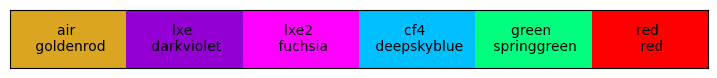

In [1]:
import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import pandas as pd
import matplotlib.pyplot as plt

from scipy import optimize as opt
from scipy.stats import norm
from scipy.stats import triang

import iminuit
from iminuit import Minuit
from scipy.ndimage import gaussian_filter1d

from PDEModel.OpticsDataLoader import *
import PDEModel.MathEquations as ME
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
# from PDEModel.PNJunction import *
import PDEModel.PNJunction as PNJ

from FittingFunctions import * 

import FittingTools.PDE_fittingTools as SS
# from FittingTools import FittingFunctions as FF

import PDEModel.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

In [2]:
def quadraticSolution(a, b, c):
    return (-b + np.sqrt(b**2 - 4*a*c))/(2*a), (-b - np.sqrt(b**2 - 4*a*c))/(2*a)

veraFWHM = 9/2.355
FF = 0.8
p = 35 # units of um
h = 1.3

## Case A
case = quadraticSolution(a = 1, b = -p, c = (1-FF)*(p**2)/4)
print("35um pitch, ff: ", case)
ff_fbk = min(case)
print("35um fbk pitch, ff: ", ff_fbk)

Wfbk = ff_fbk/p
Hfbk = h / p
print("relative Width, fbk: ", Wfbk)
print("testing FF func:", FF_theta_relative(Wfbk, Hfbk, 0))

35um pitch, ff:  (33.15247584249853, 1.8475241575014714)
35um fbk pitch, ff:  1.8475241575014714
relative Width, fbk:  0.05278640450004204
testing FF func: 0.8569469387755102


-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


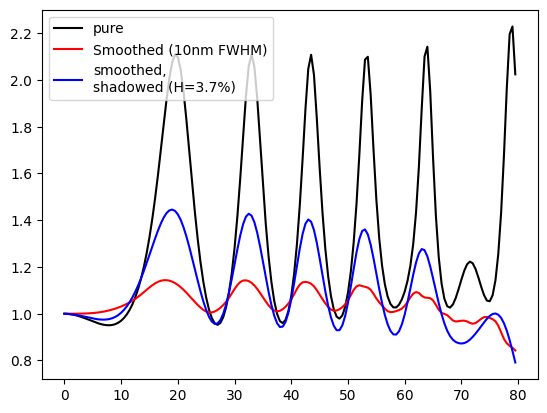

In [3]:
someAngles = np.arange(0, 80, 0.5)

yPure = RelativeTrans_oxide(wlen=160, tOxide=1390, theta1=someAngles)
ySmoothed = RelativeTrans_oxide(wlen=160, tOxide=1390, theta1=someAngles, smoothSigma=10)
yShadowed = RelativeTrans_oxide(wlen=160, tOxide=1390, theta1=someAngles, smoothSigma=2/2.335, H=Hfbk)

plt.plot(someAngles, yPure, color="black", label = "pure")
plt.plot(someAngles, ySmoothed, color="red", label = "Smoothed (10nm FWHM)")
plt.plot(someAngles, yShadowed, color="blue", label = f"smoothed,\nshadowed (H={Hfbk*100:.1f}%)")

plt.legend()

In [4]:
print("---- New Data ----")

file_pathHR = os.path.join(VERA_DATA_PATH, "FBK_STD4_Angular_beammaps_0.5mmslit_T-110C.csv")

df = pd.read_csv(file_pathHR, header=0)
# print(df.head())
# print(df.tail())

# data_anglesHR = df[strA].unique()
dfNames = df.columns
print(dfNames.values)
strV = dfNames[2]
strI = dfNames[3]
strIerr = dfNames[4]
strA = dfNames[0]
strWlen = dfNames[1]

data_voltages = df[strV].unique()
data_wlensAll = df[strWlen].unique()
print("angle range:", df[strA].min(), df[strA].max())

print("voltages:", data_voltages)
print("wavelengths:", data_wlensAll)

print("wlen range:", df['Wavelength'].min(), df['Wavelength'].max())

df['absAngle'] = df[strA] 
strA ='absAngle'

print(df.columns)
vPick = data_voltages[1]

---- New Data ----
['Angle (starting from -60deg)' 'Wavelength' 'Overvoltage' 'Current'
 'Error']
angle range: -60 13
voltages: [3 6]
wavelengths: [ 10.0116  159.952     9.98302 399.975   599.952   399.946  ]
wlen range: 9.98302 599.952
Index(['Angle (starting from -60deg)', 'Wavelength', 'Overvoltage', 'Current',
       'Error', 'absAngle'],
      dtype='object')


In [5]:
class AngularObject:
    
    def __init__(self, voltage, wavelength, yNorm, yNormErr, angles):
        self.voltage = voltage
        self.wavelength = wavelength
        self.yNorm = yNorm
        self.yNormErr = yNormErr
        self.angles = angles

[ 10.0116  159.952     9.98302 399.975   599.952   399.946  ]
proper wlens: [159.952, 399.975, 599.952]
wl: 159.952
current zero: 2.1747e-08
wl: 399.975
current zero: 6.80852e-08
wl: 599.952
current zero: 9.02288e-07


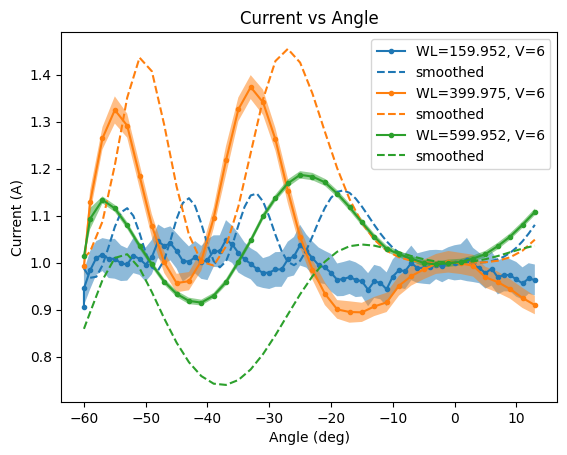

In [6]:
wlenBuf = 2.
properwlens = []
for i, wlen in enumerate(data_wlensAll):
    if abs(data_wlensAll[i - 2] - wlen) < wlenBuf or abs(data_wlensAll[i - 1] - wlen) < wlenBuf or wlen < 100:
        continue
    else:
        properwlens.append(wlen)

print(data_wlensAll)
print("proper wlens:", properwlens)
data_wlensAll = properwlens

angleObjs = []
normalRange = 1.5
for Vov in data_voltages[1:2]:
    for wl in data_wlensAll:
        df_wl = df[(df[strWlen] > wl - wlenBuf) & (df[strWlen] < wl + wlenBuf) & (df[strV] == Vov)]
        print("wl:", wl)
        
        # print(df_wl[strA].abs())
        # print(df_wl.loc[df_wl[strA].abs().idxmin()])
        
        currentNormal = df_wl.loc[df_wl[strA].abs().idxmin()][strI] # get value for minimum angle
        print("current zero:", currentNormal)

        meanCurrentNormal = df_wl.loc[(df[strA] >= -normalRange) & (df[strA] <= normalRange), strI].mean()
        meanErrorCurrentNormal = df_wl.loc[(df[strA] >= -normalRange) & (df[strA] <= normalRange), strIerr].mean() 
        # meanErrorCurrentNormal = 1
        
        xAngle = df_wl[strA].values
            
        yCurrent = df_wl[strI].values
        yErrs = df_wl[strIerr].values
        
        yNorm = yCurrent/meanCurrentNormal
        yErrsNorm = yNorm * np.sqrt((yErrs/yCurrent)**2 + (meanErrorCurrentNormal/meanCurrentNormal)**2)

        plt.plot(xAngle, yNorm,  marker = ".", label=f"WL={wl}, V={Vov}")
        plt.fill_between(xAngle, yNorm - yErrsNorm, yNorm + yErrsNorm, alpha=0.5)
        
        ax = plt.gca()
        last_line = ax.lines[-1]
        lastCol = last_line.get_color()

        angObj = AngularObject(voltage=Vov, wavelength=wl, yNorm=yNorm, yNormErr=yErrsNorm, angles=xAngle)
        if wl > 200:
            angleObjs.append(angObj)

        if Vov > 3 and wl > 0:
            yTrans = RelativeTrans_oxide(wlen=wl, tOxide=1360, theta1=xAngle, H = 0.01, smoothSigma=4)
            
            # yPDE = RelativePDE_angle(wlen=wl, tOxide=1360, theta1=xAngle, H = 0.01, smoothSigma=None)
            plt.plot(xAngle, yTrans, color=lastCol, linestyle ="--", label = "smoothed")
            yTransPure = RelativeTrans_oxide(wlen=wl, tOxide=1390+160, theta1=xAngle, H = 0.01, smoothSigma=None)
            # plt.plot(xAngle, yTransPure, color=lastCol, linestyle ="-.", label = "pure")

plt.legend()
plt.title("Current vs Angle")
plt.xlabel("Angle (deg)")
plt.ylabel("Current (A)")
plt.legend()
plt.show()

In [7]:
center=5
spacing = 10
np.arange(center-spacing, center+spacing + 1, 1)

array([-5, -4, -3, -2, -1,  0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11,
       12, 13, 14, 15])

min tox: 1390


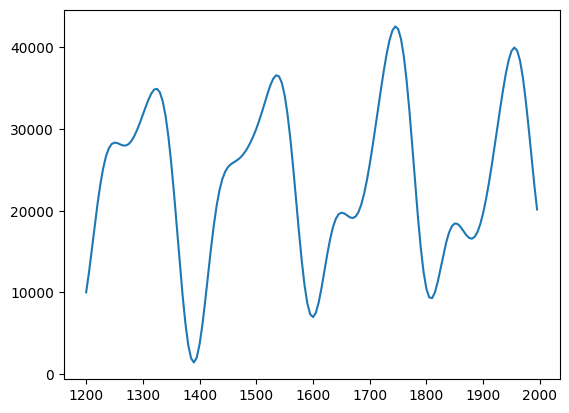

In [8]:
thickOptions = np.arange(1200, 2000, 5)
chi2s = []
for tox in thickOptions:
    chi2 = 0
    for ang in angleObjs:
        # print(ang.voltage, ang.wavelength)
        
        yTrans = RelativeTrans_oxide(wlen=ang.wavelength, tOxide=tox, theta1=ang.angles, H = 0.00, smoothSigma=2)
        
        chi2 += sum((ang.yNorm - yTrans)**2 / ang.yNormErr**2)
    chi2s.append(chi2)

plt.plot(thickOptions, chi2s)

print("min tox:", thickOptions[np.argmin(chi2s)])

In [9]:
# Building dataset for fitting. No Nuisance parameters
dataObj = []
dataPNobj = []
errorFraction = 0.1

for wl in data_wlensAll:
    df_wl = df[(df[strWlen] > wl - wlenBuf) & (df[strWlen] < wl + wlenBuf) & (df[strV] == vPick)]
    print("wl:", wl)
      
    xAngle = df_wl[strA].values
    # xAngle = max(xAngle) - xAngle
    xAngle = xAngle
    
    yCurrent = df_wl[strI].values
    yCurrentError = yCurrent * errorFraction
    
    cutoff = 4
    currentNormal = np.average(yCurrent[xAngle < cutoff])
    currentNormError = currentNormal * errorFraction / np.sqrt(len(yCurrent[xAngle < cutoff]))
    yNorm = yCurrent/currentNormal
    yNormErrors = yNorm*np.sqrt((yCurrentError/currentNormal)**2 + (yNorm * currentNormError/currentNormal)**2)
        
    thisData = {"wlen":wl, "theta1":xAngle, "yVals":yNorm, "yErrs":yNormErrors}
    thisDataPN = {"wlen":wl, "theta1":xAngle, "yVals":yNorm, "yErrs":yNormErrors}
    print(xAngle)
    
    dataObj.append(thisData)
    dataPNobj.append(thisDataPN)

wl: 159.952
[-60 -60 -59 -58 -57 -56 -55 -54 -53 -52 -51 -50 -49 -48 -47 -46 -45 -44
 -43 -42 -41 -40 -39 -38 -37 -36 -35 -34 -33 -32 -31 -30 -29 -28 -27 -26
 -25 -24 -23 -22 -21 -20 -19 -18 -17 -16 -15 -14 -13 -12 -11 -10  -9  -8
  -7  -6  -5  -4  -3  -2  -1   0   1   2   3   4   5   6   7   8   9  10
  11  12  13]
wl: 399.975
[-60 -59 -57 -55 -53 -51 -49 -47 -45 -43 -41 -39 -37 -35 -33 -31 -29 -27
 -25 -23 -21 -19 -17 -15 -13 -11  -9  -7  -5  -3  -1   1   3   5   7   9
  11  13]
wl: 599.952
[-60 -59 -57 -55 -53 -51 -49 -47 -45 -43 -41 -39 -37 -35 -33 -31 -29 -27
 -25 -23 -21 -19 -17 -15 -13 -11  -9  -7  -5  -3  -1   1   3   5   7   9
  11  13]


In [13]:
parsFixed = {"W":Wfbk, "H":0.0, "dataHelper": None, "window":False, "smoothSigma": veraFWHM}
# wlen, tOxide, theta1, FF = 1.0, 

parsFloat = {"tOxide":1300.}
floatBounds = {"tOxide": (1200, 1500)} #"smoothSigma": (-10, 100)
x0, x0Name = SS.BuildX0(parsFloat, RelativeTrans_oxide)
x0Bounds = SS.BuildX0_bounds(floatBounds, RelativeTrans_oxide)

SS.CheckAllConditions_forResiduals(func=RelativeTrans_oxide, dataObj=dataObj, dFixed=parsFixed, dFloat=parsFloat,
                                   yNames=("yVals", "yErrs"), verbose=False)

a = SS.GenericResiduals(x0=x0, dataObj = dataObj,
                               functionToFit=RelativeTrans_oxide,
                               fixedArgs_dict = parsFixed,
                               verbose=True, yNames = ("yVals", "yErrs"))
print("Guess score:", a)

------- GenericResiduals(function=RelativeTrans_oxide) -------
	all input parameters (except data):  ['tOxide', 'W', 'H', 'smoothSigma', 'dataHelper', 'window']
	floating args:  ['tOxide']
	---------------- data block 0 --------------------
		float dict (from x0): {'tOxide': 1300.0}
		fixed dict: {'W': 0.05278640450004204, 'H': 0.0, 'dataHelper': None, 'window': False, 'smoothSigma': 3.821656050955414}
		dataDict for function, (keys): {'wlen': 159.952, 'theta1': [-60, -60, -59, '...']}
		dataDict for data (y): {'yVals': [0.9089016734128443, 0.9493080746896113, 0.9879372036607051, '...'], 'yErrs': [0.08324326299631882, 0.09080915601326207, 0.0983499107586487, '...']}
	---------------- data block 1 --------------------
		float dict (from x0): {'tOxide': 1300.0}
		fixed dict: {'W': 0.05278640450004204, 'H': 0.0, 'dataHelper': None, 'window': False, 'smoothSigma': 3.821656050955414}
		dataDict for function, (keys): {'wlen': 399.975, 'theta1': [-60, -59, -57, '...']}
		dataDict for data (y)

In [14]:
## doing fit
fitResult = iminuit.minimize(SS.GenericResiduals, x0=x0, bounds = x0Bounds,
                             args=(parsFixed, dataObj, RelativeTrans_oxide),
                             method='migrad')
# options={'stra': 2, "maxfun": 1000}
print(fitResult)

resultDict = SS.GetResDict(fitResult, x0Name)
errorDict = SS.GetResErrorDict(fitResult, x0Name)
print("score:", fitResult.fun)
print(resultDict)
print(errorDict)

  message: Optimization terminated successfully.
  success: True
      fun: 263.1892159997152
        x: [ 1.269e+03]
 hess_inv: ┌────┬──────┐
           │    │   x0 │
           ├────┼──────┤
           │ x0 │ 3.46 │
           └────┴──────┘
     nfev: 25
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 263.2                      │              Nfcn = 25               │
           │ EDM = 4.58e-06 (Goal: 0.0001)    │            time = 1.3 sec            │
           ├──────────────────────────────────┼──────────────────────────────────────┤
           │          Valid Minimum           │   Below EDM threshold (goal x 10)    │
           ├──────────────────────────────────┼──────────────────────────────────────┤
           │      No parameters at

---
### Full Relative PDE equation

In [12]:
# pars fixed Full

allArgs = SS.GetFuncArgs(RelativePDE_angle)
print(allArgs)

parsPN_Fixed = {"tOxide":1339.0, "FF":0.8, "dp_star":1.26, "Xpn":320, "dw_star": 4.4e3, "quantum": False, "dh": None, "smoothSigma": veraFWHM}
# wlen, tOxide, theta1, FF = 1.0, 

parsFloat = {"pe":0.9, "ph":0.3}
floatBounds = {"pe":(0.0, 1.1), "ph": (0.0, 1.1)} #"tOxide": (1200, 1500) #"smoothSigma": (-10, 100)
x0, x0Name = SS.BuildX0(parsFloat, RelativePDE_angle)
x0Bounds = SS.BuildX0_bounds(floatBounds, RelativePDE_angle)

SS.CheckAllConditions_forResiduals(func=RelativePDE_angle, dataObj=dataPNobj, dFixed=parsPN_Fixed, dFloat=parsFloat,
                                   yNames=("yVals", "yErrs"), verbose=False)

a = SS.GenericResiduals(x0=x0, dataObj = dataPNobj,
                               functionToFit=RelativePDE_angle,
                               fixedArgs_dict = parsPN_Fixed,
                               verbose=True, yNames = ("yVals", "yErrs"))
print("Guess score:", a)

ndof = sum([len(do["theta1"]) for do in dataPNobj]) - len(parsFloat) - len(parsPN_Fixed)
print("reduced score:", a/ndof)

['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum', 'dh', 'window']
	Mistake! Keys missing. In function but not included in the dataset or float/fixed:   {'window'}
-- CheckInputKeySets_completeness(func=RelativePDE_angle) --
	Success: two extra keys in data array: {'yVals', 'yErrs'} 	(uncertainties included)
	Mistake! Keys missing. In function but not included in the dataset or float/fixed:   {'window'}
 (CheckInputKeySets_completeness) failed, should not proceed
	Error:missing or extra args passed, len(x0) + len(fixedDict) != len(argsNeeded)
		len(x0 + fixed): 10   len(nonDataArgs) 11
-- CheckInputs_forResiduals(function=RelativePDE_angle) --
	Error:missing or extra args passed, len(x0) + len(fixedDict) != len(argsNeeded)
		len(x0 + fixed): 10   len(nonDataArgs) 11
 (CheckInputs_forResiduals) failed, should not proceed
------------------------------------


ValueError: Failed one or more tests, should not proceed with GenericResiduals() function

In [ ]:
## doing the PN fit
PNfitResult = iminuit.minimize(SS.GenericResiduals, x0=x0, bounds = x0Bounds,
                             args=(parsPN_Fixed, dataPNobj, RelativePDE_angle),
                             method='migrad', options={'stra': 2, "maxfun": 1000})
print(PNfitResult)

resultDictPN = SS.GetResDict(PNfitResult, x0Name)
errorDictPN = SS.GetResErrorDict(PNfitResult, x0Name)
print("score:", PNfitResult.fun)
print(resultDictPN)
print(errorDictPN)

  message: Optimization terminated successfully, but uncertainties are unrealiable.
  success: True
      fun: 61.624437922367676
        x: [ 4.139e-01  1.648e-11]
 hess_inv: ┌────┬───────────────────────────────────┐
           │    │               x0               x1 │
           ├────┼───────────────────────────────────┤
           │ x0 │         1.29e+09 111.190243624e-3 │
           │ x1 │ 111.190243624e-3         9.58e-12 │
           └────┴───────────────────────────────────┘
     nfev: 81
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 61.62                      │              Nfcn = 81               │
           │ EDM = 1.86e-09 (Goal: 0.0001)    │            time = 4.1 sec            │
           ├──────────────────────────────────┼──